# Customer Churn & Retention Analysis

## Project Overview

This project analyzes customer churn in a telecommunications company using Python and the IBM Telco Customer Churn dataset.

**Business objective:** Identify customer groups with high churn rates, understand patterns associated with customer departures, and recommend data-driven retention strategies.

## Key Questions

- What percentage of customers leave the company?
- Which contract types, tenure groups, payment methods, and internet services are associated with higher churn?
- How do monthly charges differ between customers who leave and those who stay?
- Which customer segments should the business prioritize for retention?

## Tools

Python, Pandas, Matplotlib, Seaborn, and Jupyter Notebook

In [1]:
import sys
print(sys.executable)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

/Users/charithadevara/Desktop/customer-churn-retention-analysis/.venv/bin/python
All libraries imported successfully!


In [2]:
import pandas as pd

df = pd.read_csv("Data/Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Check column names, data types, and non-null values
df.info()

# Check missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# Count blank or whitespace-only TotalCharges values
blank_charges = df["TotalCharges"].str.strip().eq("").sum()

print("Blank TotalCharges values:", blank_charges)

# Display the affected records
df.loc[df["TotalCharges"].str.strip().eq(""), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Blank TotalCharges values: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [5]:
# Remove extra whitespace
df["TotalCharges"] = df["TotalCharges"].str.strip()

# Replace blank charges with 0 for customers with zero tenure
df["TotalCharges"] = df["TotalCharges"].replace("", "0")

# Convert TotalCharges from text to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"])

# Verify the cleaning
print("TotalCharges data type:", df["TotalCharges"].dtype)
print("Remaining missing values:", df["TotalCharges"].isnull().sum())
print("Customers with zero tenure:", (df["tenure"] == 0).sum())

df.loc[df["tenure"] == 0, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

TotalCharges data type: float64
Remaining missing values: 0
Customers with zero tenure: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,0.0,No
753,3115-CZMZD,0,20.25,0.0,No
936,5709-LVOEQ,0,80.85,0.0,No
1082,4367-NUYAO,0,25.75,0.0,No
1340,1371-DWPAZ,0,56.05,0.0,No
3331,7644-OMVMY,0,19.85,0.0,No
3826,3213-VVOLG,0,25.35,0.0,No
4380,2520-SGTTA,0,20.00,0.0,No
5218,2923-ARZLG,0,19.70,0.0,No
6670,4075-WKNIU,0,73.35,0.0,No


In [6]:
# Count customers who churned and those who stayed
churn_counts = df["Churn"].value_counts()

print("Customer counts:")
print(churn_counts)

# Calculate overall churn rate
churn_rate = (df["Churn"] == "Yes").mean() * 100

print(f"\nOverall churn rate: {churn_rate:.2f}%")

# Calculate the percentage who stayed
retention_rate = (df["Churn"] == "No").mean() * 100

print(f"Overall retention rate: {retention_rate:.2f}%")

Customer counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Overall churn rate: 26.54%
Overall retention rate: 73.46%


Churn rate by contract type:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


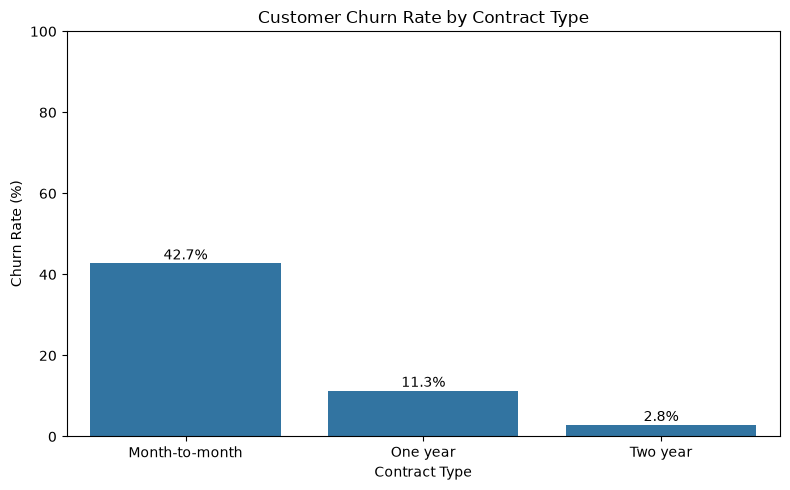

In [7]:
# Calculate churn rate for each contract type
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Churn rate by contract type:")
print(contract_churn.round(2))

# Visualize the results
plt.figure(figsize=(8, 5))
sns.barplot(x=contract_churn.index, y=contract_churn.values)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

for i, value in enumerate(contract_churn.values):
    plt.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

Churn rate by customer tenure:
TenureGroup
0–6 months      52.94
7–12 months     35.89
13–24 months    28.71
25–48 months    20.39
49–72 months     9.51
Name: Churn, dtype: float64


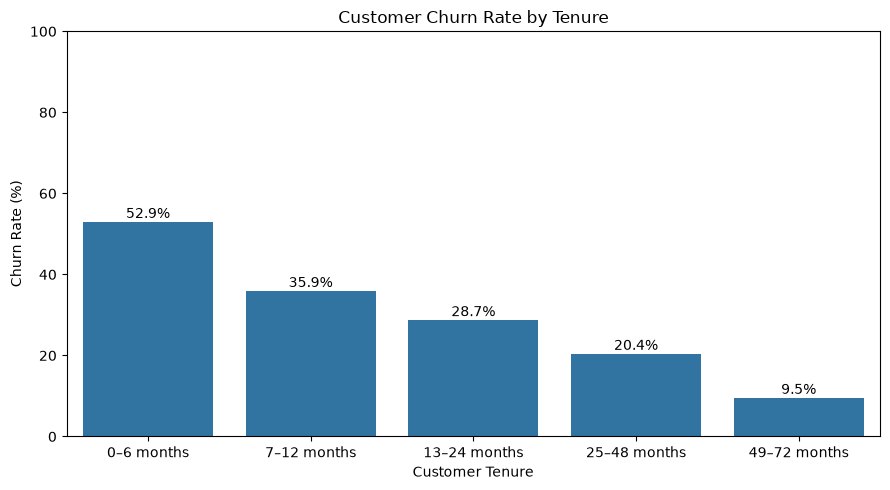

In [8]:
# Group customers by how long they have stayed
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0–6 months", "7–12 months", "13–24 months",
            "25–48 months", "49–72 months"]
)

# Calculate churn rate for each tenure group
tenure_churn = (
    df.groupby("TenureGroup", observed=False)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

print("Churn rate by customer tenure:")
print(tenure_churn.round(2))

# Create the chart
plt.figure(figsize=(9, 5))
sns.barplot(x=tenure_churn.index, y=tenure_churn.values)

plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

for i, value in enumerate(tenure_churn.values):
    plt.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

Churn rate by payment method:
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64


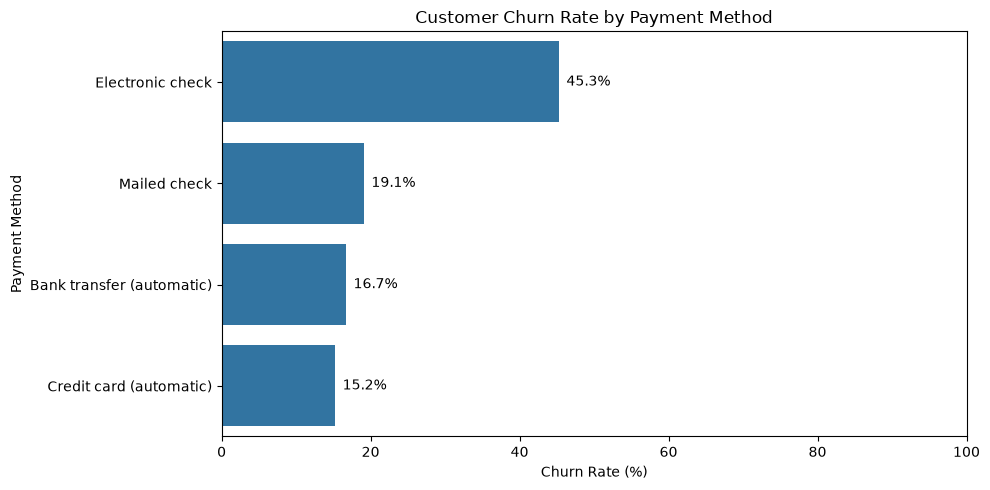

In [9]:
# Calculate churn rate by payment method
payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Churn rate by payment method:")
print(payment_churn.round(2))

# Visualize the results
plt.figure(figsize=(10, 5))
sns.barplot(x=payment_churn.values, y=payment_churn.index)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Payment Method")
plt.xlim(0, 100)

for i, value in enumerate(payment_churn.values):
    plt.text(value + 1, i, f"{value:.1f}%", va="center")

plt.tight_layout()
plt.show()

Churn rate by internet service:
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64


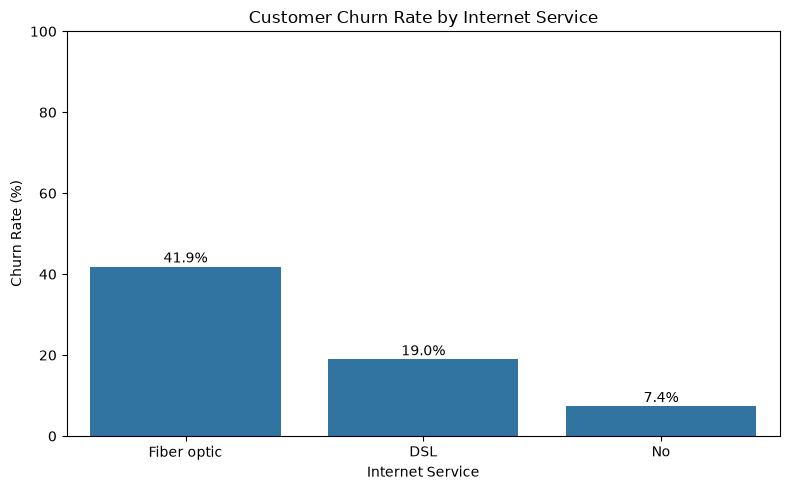

In [10]:
# Calculate churn rate by internet service
internet_churn = (
    df.groupby("InternetService")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Churn rate by internet service:")
print(internet_churn.round(2))

# Visualize the results
plt.figure(figsize=(8, 5))
sns.barplot(x=internet_churn.index, y=internet_churn.values)

plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

for i, value in enumerate(internet_churn.values):
    plt.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

Monthly charges by churn status:
       count   mean  median
Churn                      
No      5174  61.27   64.43
Yes     1869  74.44   79.65


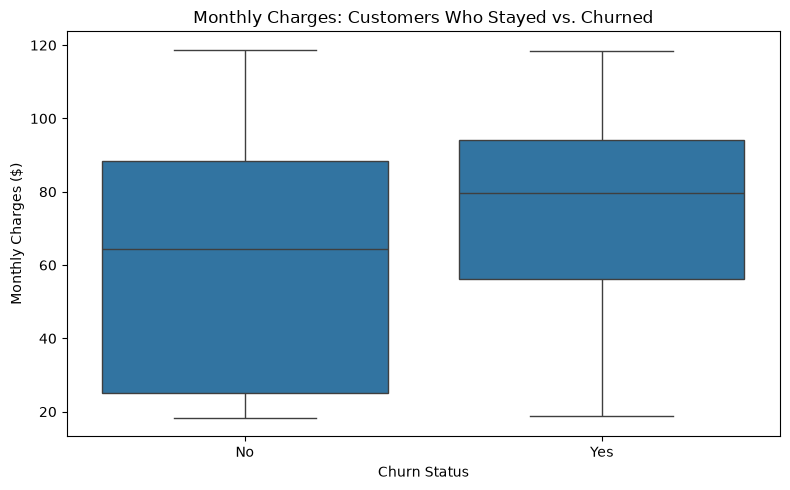

In [11]:
# Summarize monthly charges by churn status
charges_summary = df.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median"]
)

print("Monthly charges by churn status:")
print(charges_summary.round(2))

# Visualize the distributions
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges: Customers Who Stayed vs. Churned")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges ($)")

plt.tight_layout()
plt.show()

Churn rate by online security:
OnlineSecurity
No                     41.77
Yes                    14.61
No internet service     7.40
Name: Churn, dtype: float64


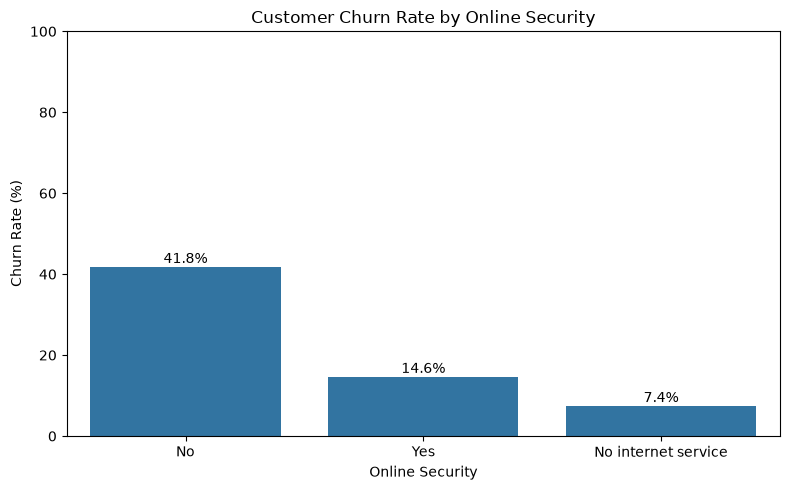

In [12]:
# Calculate churn rate by online security subscription
security_churn = (
    df.groupby("OnlineSecurity")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Churn rate by online security:")
print(security_churn.round(2))

# Visualize the results
plt.figure(figsize=(8, 5))
sns.barplot(x=security_churn.index, y=security_churn.values)

plt.title("Customer Churn Rate by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

for i, value in enumerate(security_churn.values):
    plt.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()

Churn rate by Tech Support:
TechSupport
No                     41.64
Yes                    15.17
No internet service     7.40
Name: Churn, dtype: float64


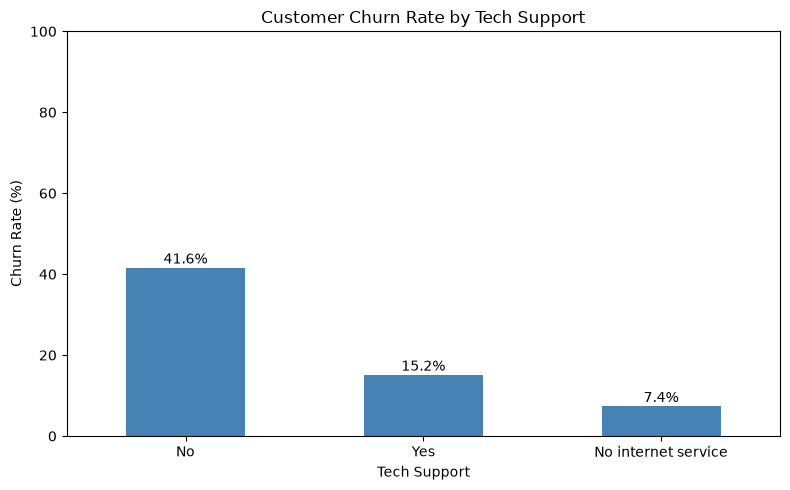

In [13]:
# Calculate churn rate by tech support status
tech_support_churn = (
    df.groupby("TechSupport")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Churn rate by Tech Support:")
print(tech_support_churn.round(2))

# Create a chart
plt.figure(figsize=(8, 5))
ax = tech_support_churn.plot(kind="bar", color="steelblue")

plt.title("Customer Churn Rate by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)

for i, value in enumerate(tech_support_churn):
    ax.text(i, value + 1, f"{value:.1f}%", ha="center")

plt.tight_layout()
plt.show()


## Key Findings: Customer Churn Analysis

### 1. Overall Churn
- Total customers: 7,043
- Customers who left: 1,869
- Overall churn rate: 26.54%
- Retention rate: 73.46%

### 2. Contract Type
Month-to-month customers have a 42.7% churn rate, compared with 11.3% for one-year contracts and 2.8% for two-year contracts.

### 3. Customer Tenure
Customers with 0–6 months of tenure have the highest churn rate at 52.9%. Churn generally decreases as tenure increases.

### 4. Payment Method
Customers paying by electronic check have a 45.3% churn rate, higher than customers using automatic payment methods.

### 5. Internet Service
Fiber-optic customers have a 41.9% churn rate, compared with 19.0% for DSL customers and 7.4% for customers without internet service.

### 6. Additional Services
Customers without online security have a 41.8% churn rate. Customers without tech support have a 41.6% churn rate.

### 7. Monthly Charges
Customers who churned had a median monthly charge of $79.65, compared with $64.43 for customers who stayed.

## Business Recommendations

1. Focus retention efforts on customers during their first six months.
2. Encourage month-to-month customers to consider longer-term contracts.
3. Investigate pricing and service concerns among fiber-optic customers.
4. Evaluate targeted online security and tech support offers.
5. Review the customer experience for electronic-check users.

**Important:** These findings show associations, not proof of causation.


In [14]:

# Calculate monthly revenue associated with churned customers

churned_customers = df[df["Churn"] == "Yes"]
retained_customers = df[df["Churn"] == "No"]

churned_revenue = churned_customers["MonthlyCharges"].sum()
retained_revenue = retained_customers["MonthlyCharges"].sum()

print("Customers who churned:", len(churned_customers))
print("Customers retained:", len(retained_customers))
print(f"Monthly charges associated with churned customers: ${churned_revenue:,.2f}")
print(f"Monthly charges associated with retained customers: ${retained_revenue:,.2f}")


Customers who churned: 1869
Customers retained: 5174
Monthly charges associated with churned customers: $139,130.85
Monthly charges associated with retained customers: $316,985.75


In [15]:

total_monthly_charges = df["MonthlyCharges"].sum()

churned_revenue_percentage = (
    churned_revenue / total_monthly_charges
) * 100

print(f"Total monthly charges: ${total_monthly_charges:,.2f}")
print(f"Percentage associated with churned customers: {churned_revenue_percentage:.2f}%")


Total monthly charges: $456,116.60
Percentage associated with churned customers: 30.50%


In [16]:
# Count churned customers by contract type
contract_summary = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

contract_summary["Total Customers"] = contract_summary.sum(axis=1)
contract_summary["Churn Rate (%)"] = (
    contract_summary["Yes"] / contract_summary["Total Customers"] * 100
)

print(contract_summary.round(2))

Churn             No   Yes  Total Customers  Churn Rate (%)
Contract                                                   
Month-to-month  2220  1655             3875           42.71
One year        1307   166             1473           11.27
Two year        1647    48             1695            2.83


In [17]:
# Compare churn across contract, tenure group, and payment method
risk_summary = (
    df.groupby(
        ["Contract", "TenureGroup", "PaymentMethod"],
        observed=True
    )
    .agg(
        Total_Customers=("Churn", "size"),
        Churned_Customers=("Churn", lambda x: (x == "Yes").sum())
    )
)

risk_summary["Churn_Rate_Pct"] = (
    risk_summary["Churned_Customers"]
    / risk_summary["Total_Customers"] * 100
)

# Focus on groups with at least 30 customers
risk_summary = risk_summary[
    risk_summary["Total_Customers"] >= 30
]

print("Highest-churn customer segments (minimum 30 customers):")
print(
    risk_summary.sort_values("Churn_Rate_Pct", ascending=False)
    .head(10)
    .round(2)
)

Highest-churn customer segments (minimum 30 customers):
                                                       Total_Customers  \
Contract       TenureGroup  PaymentMethod                                
Month-to-month 0–6 months   Electronic check                       680   
                            Bank transfer (automatic)              110   
               7–12 months  Electronic check                       274   
               13–24 months Electronic check                       355   
               0–6 months   Credit card (automatic)                119   
               25–48 months Electronic check                       376   
               0–6 months   Mailed check                           504   
               7–12 months  Bank transfer (automatic)               98   
                            Credit card (automatic)                 72   
               49–72 months Electronic check                       165   

                                                       


## High-Risk Customer Segments

### Highest-Priority Segment
Customers with month-to-month contracts, 0–6 months of tenure, and electronic-check payments had a 67.65% churn rate. Of 680 customers in this segment, 460 churned.

### Recommended Retention Actions

1. **Improve early onboarding:** Contact new customers during their first six months to identify service problems and billing confusion.
2. **Test contract incentives:** Offer eligible month-to-month customers a transparent incentive to consider an annual contract.
3. **Investigate electronic-check customers:** Review billing complaints, payment friction, contract distribution, and customer experience before assuming the payment method causes churn.
4. **Review service quality and pricing:** Investigate high churn among fiber-optic customers and customers with higher monthly charges.
5. **Measure outcomes:** Run a controlled retention campaign and compare churn rates between customers who receive the intervention and a suitable control group.

### Business Caveat

The analysis identifies associations in historical customer data. It does not prove causation or establish how much churn a retention campaign can prevent. Recommendations should be validated through further analysis and testing.


In [18]:
summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Overall Churn Rate",
        "Month-to-Month Churn Rate",
        "First 6 Months Churn Rate",
        "Electronic Check Churn Rate",
        "Fiber Optic Churn Rate",
        "Average Monthly Charges - Churned",
        "Average Monthly Charges - Retained"
    ],
    "Value": [
        len(df),
        round((df["Churn"] == "Yes").mean() * 100, 2),
        round(df.loc[df["Contract"] == "Month-to-month", "Churn"].eq("Yes").mean() * 100, 2),
        round(df.loc[df["TenureGroup"] == "0–6 months", "Churn"].eq("Yes").mean() * 100, 2),
        round(df.loc[df["PaymentMethod"] == "Electronic check", "Churn"].eq("Yes").mean() * 100, 2),
        round(df.loc[df["InternetService"] == "Fiber optic", "Churn"].eq("Yes").mean() * 100, 2),
        round(df.loc[df["Churn"] == "Yes", "MonthlyCharges"].mean(), 2),
        round(df.loc[df["Churn"] == "No", "MonthlyCharges"].mean(), 2)
    ]
})

summary

,Metric,Value
0,Total Customers,7043.00
1,Overall Churn Rate,26.54
2,Month-to-Month Churn Rate,42.71
3,First 6 Months Churn Rate,52.94
4,Electronic Check Churn Rate,45.29
5,Fiber Optic Churn Rate,41.89
6,Average Monthly Charges - Churned,74.44
7,Average Monthly Charges - Retained,61.27


In [19]:
summary.to_csv("churn_summary.csv", index=False)

print("Summary exported successfully!")

Summary exported successfully!
